# 06 · Neural network, part A (choose and train the source network)

This notebook chooses the shape of the network and how to train it, using **only the source** (TCGA + METABRIC). Then it trains the final network with the 2,860 patients. That network is **strategy 1** (apply directly) and the starting point of **strategy 2** (fine-tuning).

A **dense network (MLP)** is a chain of layers. Each layer combines the genes (or the previous layer) and passes the result to the next one. The last layer gives the probability that TP53 is mutated.

Before training, there are things the network does not learn by itself (**hyperparameters**):
1. How many layers and neurons it has.
2. The **learning rate**: how big the steps are when it corrects its errors.
3. The **batch**: how many patients it looks at before it corrects itself.
4. The **dropout**: how many neurons it switches off at random in each step, so that it does not memorize.
5. The **optimizer**: the rule it uses to correct itself (Adam or SGD).

They are chosen by testing combinations with **5-fold cross-validation inside the source**. The values come from the literature (Hanczar et al. 2022, Sabbatini et al. 2026, Yang et al. 2023, STAMP and Triantafyllidis et al. 2025). CPTAC and SMC are **not loaded** in this notebook.

**Engine:** Keras 3 running on PyTorch. TensorFlow crashes on import on macOS 26.4, and the Keras code is the same.

**Input:** `X_tcga_brca.parquet`, `X_metabric.parquet` and their `y_*.csv` files.
**Output:** `results/tables/06_busqueda.csv` (search), `06_historiales.csv` (loss and AUC per epoch of each network), `06_elegida.json` (chosen combination) and `data/experiment/red_fuente.keras` (final network).

**Time:** it was run on the Khipu cluster (32 CPU cores) in less than 24 hours. The search saves each combination when it finishes and continues from the last one if it stops.

*Note: this notebook was run before the repository was translated. The code comments, printed text and figure labels in the saved outputs are in Spanish. The results are the same.*

In [1]:
import itertools
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from common import armar_red, fuente, pesos_clase  # common sets Keras to run on PyTorch before keras is imported

import keras

EXP = ROOT / "data" / "experiment"
FIG = ROOT / "results" / "figures"
TAB = ROOT / "results" / "tables"
SEARCH, HIST = TAB / "06_busqueda.csv", TAB / "06_historiales.csv"
MAX_EPOCHS, PATIENCE = 200, 10
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Step 1 · Load and normalize the source

Same as notebook 05: TCGA and METABRIC, each one with its own mean and SD (`common.fuente`).

In [2]:
X_src, y_src, cohort_src = fuente()
X, y = X_src.to_numpy(), y_src.to_numpy()
strata = cohort_src + "_" + y_src.astype(str)
folds = list(StratifiedKFold(5, shuffle=True, random_state=2026).split(X, strata))
print(f"{len(y):,} pacientes · {X.shape[1]:,} genes · {100 * y.mean():.1f}% mutados")

2,860 pacientes · 18,040 genes · 34.6% mutados


## Step 2 · The combinations that are tested

| Hyperparameter | Values | Why |
|---|---|---|
| Layers | `[256]`, `[512, 128]`, `[512, 256, 128]` | 1–3 layers that get smaller (Sabbatini). The last one is the network of Yang for TP53 |
| Learning rate | 1e-4, 3e-4, 1e-3 | STAMP used 1e-4; range of Triantafyllidis |
| Batch | 16, 32 | Small batches worked better (Hanczar); STAMP used 10, Triantafyllidis 16 |
| Dropout | 0, 0.3 | Hanczar found no gain; the other papers use it |
| Optimizer | Adam, SGD | SGD was more stable (Hanczar). SGD uses momentum 0.9, the usual value |

- **Class weights:** a mistake on a mutated tumor costs more, in proportion to how many fewer they are.
- **Early stopping:** training stops when the validation AUC does not improve for 10 epochs (patience of STAMP), with a maximum of 200. The best epoch is recorded.

In [3]:
GRID = [dict(capas=c, tasa=t, lote=b, dropout=d, optimizador=o)
        for c, t, b, d, o in itertools.product([[256], [512, 128], [512, 256, 128]], [1e-4, 3e-4, 1e-3],
                                               [16, 32], [0.0, 0.3], ["adam", "sgd"])]
print(len(GRID), "combinaciones ×", len(folds), "particiones =", len(GRID) * len(folds), "redes")

72 combinaciones × 5 particiones = 360 redes


## Step 3 · Measure how long one network takes

Three epochs of the largest network are trained with batch 16 on the first fold. This gives an estimate of the total time, to know when the search will finish.

Dropout (0 and 0.3) is always tested, even if it makes the search longer. It is the usual way to slow down memorization, and almost every paper uses it.

In [4]:
tr, va = folds[0]
keras.utils.set_random_seed(2026)
model = armar_red([512, 256, 128], 0.0, 1e-4, "adam")
start = time.time()
model.fit(X[tr], y[tr], batch_size=16, epochs=3, validation_data=(X[va], y[va]), class_weight=pesos_clase(y[tr]), verbose=0)
per_epoch = (time.time() - start) / 3
print(f"{per_epoch:.1f} s por época con la red más grande")
print(f"Si cada red entrena ~50 épocas: ~{per_epoch * 50 * len(GRID) * len(folds) / 3600:.0f} horas para toda la búsqueda")

12.7 s por época con la red más grande
Si cada red entrena ~50 épocas: ~63 horas para toda la búsqueda


## Step 4 · Search

For each combination and each fold: the network is trained with 4 parts of the source and its AUC is measured on the fifth one. The best validation AUC and the epoch where it happened are recorded. Every network uses seed 2026.

In [5]:
def key(c):
    return f"{c['capas']}|{c['tasa']}|{c['lote']}|{c['dropout']}|{c['optimizador']}"


done = set(pd.read_csv(SEARCH).combinacion) if SEARCH.exists() else set()
for c in GRID:
    if key(c) in done:
        continue
    start, rows, hist = time.time(), [], []
    for f, (tr, va) in enumerate(folds):
        keras.utils.set_random_seed(2026)
        model = armar_red(c["capas"], c["dropout"], c["tasa"], c["optimizador"])
        stop = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=PATIENCE)
        h = model.fit(X[tr], y[tr], batch_size=c["lote"], epochs=MAX_EPOCHS, validation_data=(X[va], y[va]),
                      class_weight=pesos_clase(y[tr]), callbacks=[stop], verbose=0).history
        best = int(np.argmax(h["val_auc"]))
        rows.append({"combinacion": key(c), **c, "capas": str(c["capas"]), "particion": f,
                     "auc_validacion": h["val_auc"][best], "mejor_epoca": best + 1})
        hist += [{"combinacion": key(c), "particion": f, "epoca": e + 1, "perdida": h["loss"][e],
                  "perdida_validacion": h["val_loss"][e], "auc": h["auc"][e], "auc_validacion": h["val_auc"][e]}
                 for e in range(len(h["loss"]))]
    pd.DataFrame(rows).to_csv(SEARCH, mode="a", header=not SEARCH.exists(), index=False)
    pd.DataFrame(hist).to_csv(HIST, mode="a", header=not HIST.exists(), index=False)
    print(f"{key(c)}: AUC {np.mean([r['auc_validacion'] for r in rows]):.3f} en {(time.time() - start) / 60:.1f} min")

[256]|0.0001|16|0.0|adam: AUC 0.934 en 4.5 min


[256]|0.0001|16|0.0|sgd: AUC 0.936 en 5.2 min


[256]|0.0001|16|0.3|adam: AUC 0.937 en 4.6 min


[256]|0.0001|16|0.3|sgd: AUC 0.942 en 4.6 min


[256]|0.0001|32|0.0|adam: AUC 0.937 en 3.3 min


...

[512, 256, 128]|0.001|16|0.3|sgd: AUC 0.938 en 4.5 min


[512, 256, 128]|0.001|32|0.0|adam: AUC 0.922 en 7.6 min


[512, 256, 128]|0.001|32|0.0|sgd: AUC 0.937 en 2.8 min


[512, 256, 128]|0.001|32|0.3|adam: AUC 0.940 en 6.6 min


[512, 256, 128]|0.001|32|0.3|sgd: AUC 0.939 en 3.4 min


## Step 5 · Choose

The highest mean validation AUC is chosen. If another combination is less than 0.005 below and its network is smaller, the smaller one is chosen. With the same quality, it has fewer weights to fit.

In [6]:
search = pd.read_csv(SEARCH)
summary = (search.groupby(["combinacion", "capas", "tasa", "lote", "dropout", "optimizador"])
           .agg(auc=("auc_validacion", "mean"), de=("auc_validacion", "std"), epocas=("mejor_epoca", "mean"))
           .reset_index().sort_values("auc", ascending=False))
summary["tamaño"] = summary.capas.map(lambda s: sum(json.loads(s)))
near = summary[summary.auc >= summary.auc.max() - 0.005]
chosen = near.sort_values(["tamaño", "auc"], ascending=[True, False]).iloc[0]
summary.head(10).round(4)

,combinacion,capas,tasa,lote,dropout,optimizador,auc,de,epocas,tamaño
11,[256]|0.0003|16|0.3|sgd,[256],0.0003,16,0.3,sgd,0.9431,0.0113,18.8,256
23,[256]|0.001|32|0.3|sgd,[256],0.0010,32,0.3,sgd,0.9428,0.0114,14.4,256
15,[256]|0.0003|32|0.3|sgd,[256],0.0003,32,0.3,sgd,0.9427,0.0117,26.8,256
7,[256]|0.0001|32|0.3|sgd,[256],0.0001,32,0.3,sgd,0.9418,0.0119,53.8,256
35,"[512, 128]|0.0003|16|0.3|sgd","[512, 128]",0.0003,16,0.3,sgd,0.9418,0.0154,20.0,640
3,[256]|0.0001|16|0.3|sgd,[256],0.0001,16,0.3,sgd,0.9417,0.0121,24.2,256
39,"[512, 128]|0.0003|32|0.3|sgd","[512, 128]",0.0003,32,0.3,sgd,0.9417,0.0168,28.6,640
43,"[512, 128]|0.001|16|0.3|sgd","[512, 128]",0.0010,16,0.3,sgd,0.9416,0.0128,7.4,640
19,[256]|0.001|16|0.3|sgd,[256],0.0010,16,0.3,sgd,0.9414,0.0117,9.6,256
47,"[512, 128]|0.001|32|0.3|sgd","[512, 128]",0.0010,32,0.3,sgd,0.9403,0.0153,8.6,640


In [7]:
print("Elegida:", chosen.combinacion, f"· AUC {chosen.auc:.3f} (DE {chosen.de:.3f}) · {chosen.epocas:.0f} épocas en promedio")

Elegida: [256]|0.0003|16|0.3|sgd · AUC 0.943 (DE 0.011) · 19 épocas en promedio


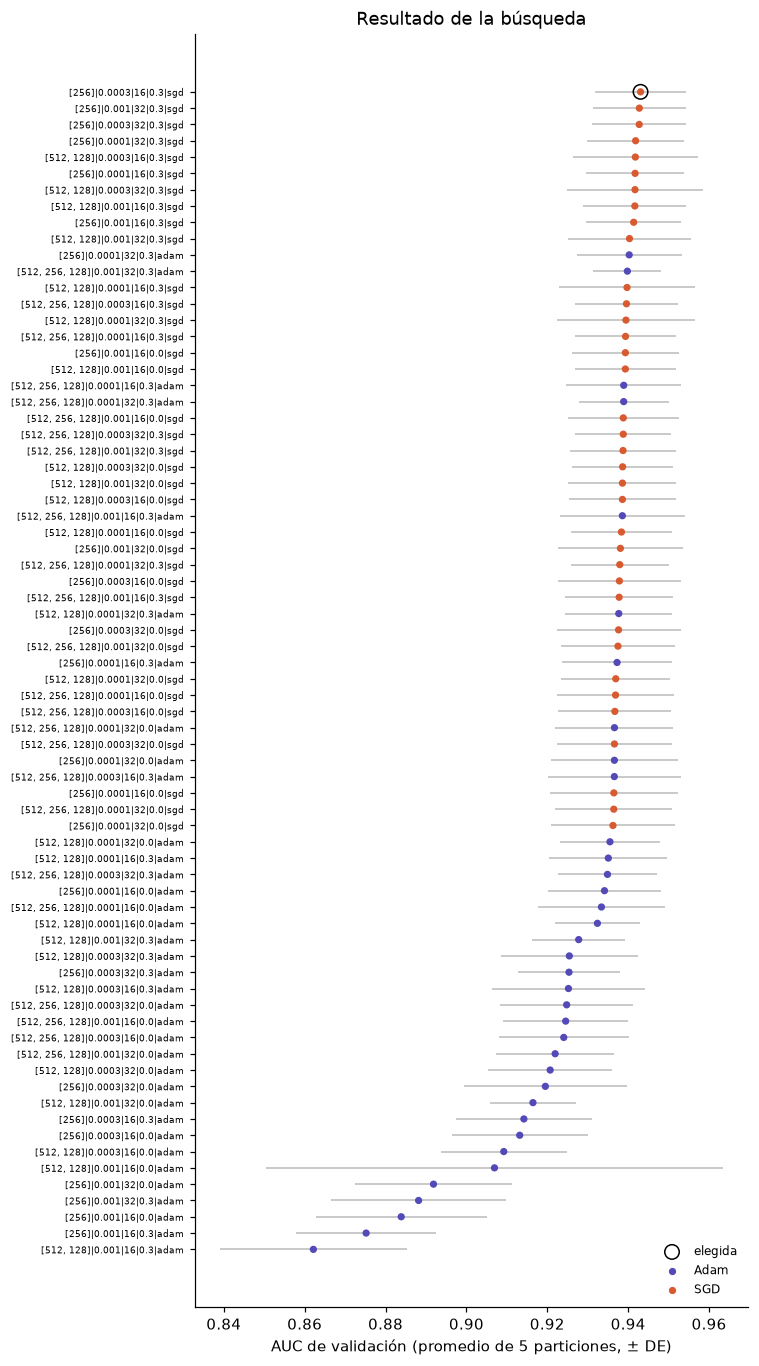

In [8]:
fig, ax = plt.subplots(figsize=(7, 0.16 * len(summary) + 1))
order = summary.sort_values("auc")
colors = order.optimizador.map({"adam": "#534AB7", "sgd": "#D85A30"})
ax.errorbar(order.auc, range(len(order)), xerr=order.de, fmt="none", ecolor="#BBBBBB", lw=1)
ax.scatter(order.auc, range(len(order)), c=colors, s=14, zorder=3)
pos = list(order.combinacion).index(chosen.combinacion)
ax.scatter(chosen.auc, pos, s=90, facecolors="none", edgecolors="black", zorder=4, label="elegida")
ax.set_yticks(range(len(order)), order.combinacion, fontsize=6)
ax.set_xlabel("AUC de validación (promedio de 5 particiones, ± DE)")
ax.scatter([], [], c="#534AB7", s=14, label="Adam")
ax.scatter([], [], c="#D85A30", s=14, label="SGD")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Resultado de la búsqueda")
plt.tight_layout()
fig.savefig(FIG / "06_busqueda.png", bbox_inches="tight")

**How to read it:** each point is one combination (layers | learning rate | batch | dropout | optimizer). The gray bars show how much it changes across the 5 folds. When many combinations are together at the top, the choice matters little, as Hanczar et al. found.

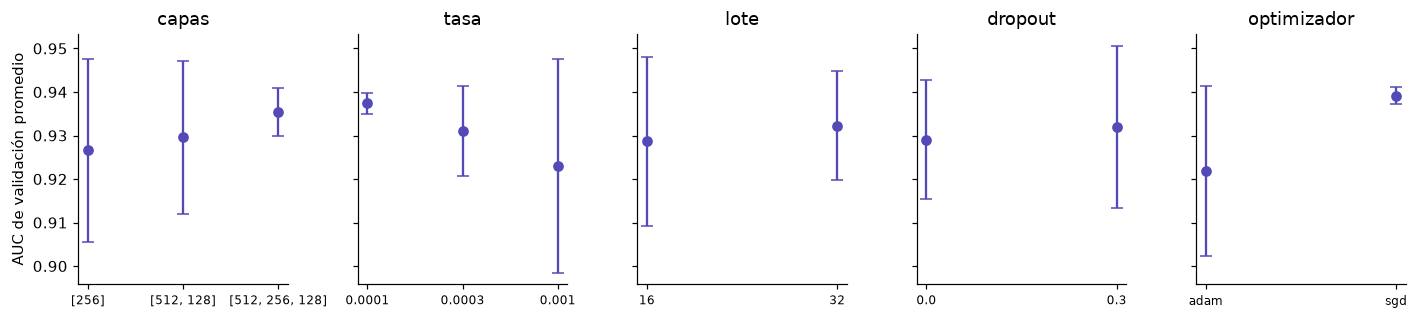

In [9]:
params = ["capas", "tasa", "lote", "dropout", "optimizador"]
fig, axes = plt.subplots(1, len(params), figsize=(13, 3), sharey=True)
for ax, p in zip(axes, params):
    g = summary.groupby(p).auc
    ax.errorbar(range(len(g.mean())), g.mean(), yerr=g.std(), marker="o", capsize=4, ls="none", color="#534AB7")
    ax.set_xticks(range(len(g.mean())), g.mean().index, fontsize=8)
    ax.set_title(p)
axes[0].set_ylabel("AUC de validación promedio")
plt.tight_layout()
fig.savefig(FIG / "06_efecto_hiperparametros.png", bbox_inches="tight")

**How to read it:** each panel averages every combination with that value. The panel with the largest difference between values is the hyperparameter that matters most.

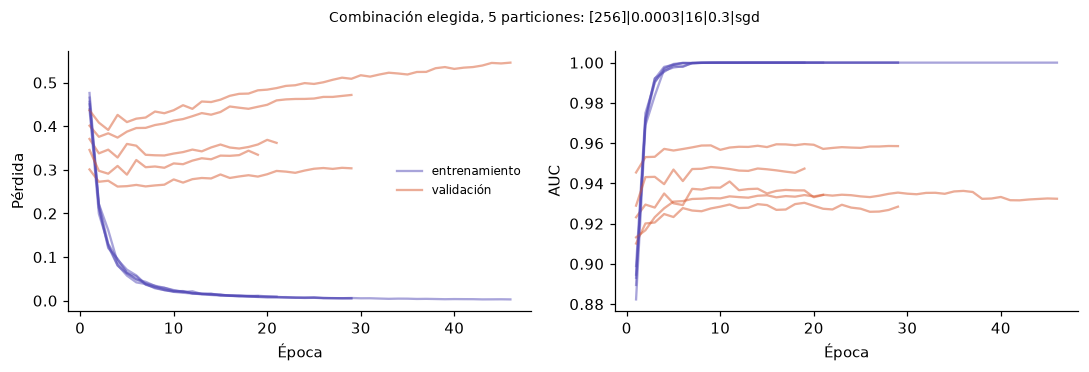

In [10]:
hist = pd.read_csv(HIST).query("combinacion == @chosen.combinacion")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for f, h in hist.groupby("particion"):
    axes[0].plot(h.epoca, h.perdida, color="#534AB7", alpha=0.5, label="entrenamiento" if f == 0 else None)
    axes[0].plot(h.epoca, h.perdida_validacion, color="#D85A30", alpha=0.5, label="validación" if f == 0 else None)
    axes[1].plot(h.epoca, h.auc, color="#534AB7", alpha=0.5)
    axes[1].plot(h.epoca, h.auc_validacion, color="#D85A30", alpha=0.5)
axes[0].set_ylabel("Pérdida")
axes[1].set_ylabel("AUC")
for ax in axes:
    ax.set_xlabel("Época")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Combinación elegida, 5 particiones: {chosen.combinacion}", fontsize=9)
plt.tight_layout()
fig.savefig(FIG / "06_curvas_entrenamiento.png", bbox_inches="tight")

**How to read it:** one line per fold. When the validation curve (orange) stops improving and the training curve (purple) keeps going, the network starts to memorize. That is where early stopping cuts.

## Step 6 · Train the final network

With the 2,860 patients, the chosen combination and the mean number of epochs of the search. There is no validation here to stop, so that fixed number is used. Seed 2026.

This network is strategy 1 and the starting point of fine-tuning (strategy 2).

In [11]:
best = dict(capas=json.loads(chosen.capas), tasa=float(chosen.tasa), lote=int(chosen.lote),
            dropout=float(chosen.dropout), optimizador=chosen.optimizador, epocas=int(round(chosen.epocas)),
            auc_validacion=round(float(chosen.auc), 4))
keras.utils.set_random_seed(2026)
model = armar_red(best["capas"], best["dropout"], best["tasa"], best["optimizador"])
model.fit(X, y, batch_size=best["lote"], epochs=best["epocas"], class_weight=pesos_clase(y), verbose=0)
model.save(EXP / "red_fuente.keras")
(TAB / "06_elegida.json").write_text(json.dumps(best, indent=2))
best

{'capas': [256],
 'tasa': 0.0003,
 'lote': 16,
 'dropout': 0.3,
 'optimizador': 'sgd',
 'epocas': 19,
 'auc_validacion': 0.9431}